Import the modules that will be used.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

## Exercise 11.1

Determine by counting the number of mathematical operations the complexity of:

1. Dot product between two vectors
1. Matrix-vector product
1. Matrix-matrix product

for vectors of length $n$ and matrices of size $n \times n$.

This is a reasoning exercise - you do not need to write a program. Express your answers in text and using LaTeX in a Markdown cell.


### Optional

Test the complexity experimentally with your own functions for performing the operations, and
with the NumPy 'vectorised' equivalents.

1. O(n)
u dot v = uivi --> n
n-1 additions
2n-1 --> O(n)

2. O(n^2)
per row:
    n multiplications
    n-1 additions
    2n-1
(2n-1)*n(rows) --> 2n^2-n --> O(n**2)

3. O(n^3)
per row and per column:
    n multiplications
    n-1 additions
    2n-1
(2n-1)*n(rows)*n(columns) --> 2n^3-n^2 --> O(n**3)



## Exercise 11.2

For the recursive factorial algorithm in Activity 04, determine the algorithmic complexity by inspecting your implementation of the algorithm. Test this against numerical experiments.

### Solution

Recall the factorial algorithm from Activity 04.4:

In [2]:
def factorial(n):
    if n==0:
        return 1
    else:
        return (factorial(n-1))*n

The function calls itself (recursively) $n$ times, hence it has complexity $O(n)$. We test this below and plot
the times.

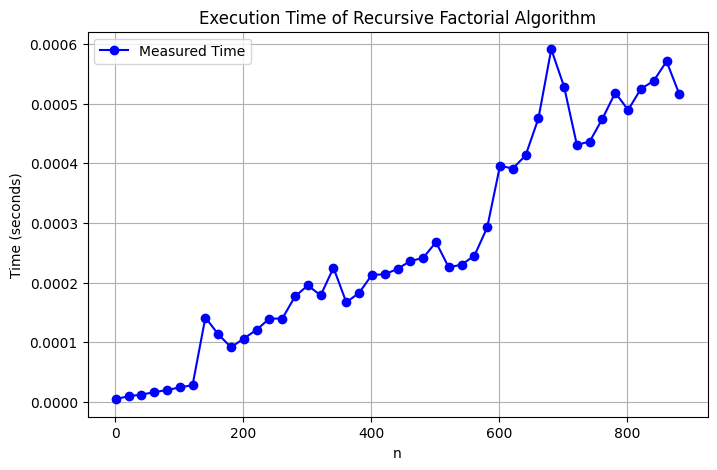

In [3]:
import time
import matplotlib.pyplot as plt

def factorial(n):
    if n == 0:
        return 1
    else:
        return (factorial(n - 1)) * n

# Define a range of values for n
n_values = list(range(1, 900, 20))
times = []

# Measure execution time for each n
for n in n_values:
    start_time = time.perf_counter()
    factorial(n)
    end_time = time.perf_counter()
    times.append(end_time - start_time)

# Plot the execution times
plt.figure(figsize=(8, 5))
plt.plot(n_values, times, marker='o', linestyle='-', color='b', label='Measured Time')
plt.xlabel('n')
plt.ylabel('Time (seconds)')
plt.title('Execution Time of Recursive Factorial Algorithm')
plt.grid(True)
plt.legend()
plt.show()

## Exercise 11.3

Determine experimentally the complexity of computing the determinant of a matrix. You can generate an $n \times n$ matrix using:

In [4]:
n = 100
A = np.random.rand(n, n)

and the determinant can be computed by:

In [5]:
det = np.linalg.slogdet(A)

Be sure that you test for sufficiently large $n$ to get into the 'large' $n$ regime.

### Solution

Time computation of determinant:

In [6]:
# Create array of problem sizes we want to test (powers of 2)
N = 2**np.arange(2, 12)
 
times = []

for n in N:
    A = np.random.rand(n, n)
    
    start_time = time.perf_counter()
    det = np.linalg.slogdet(A)
    end_time = time.perf_counter()
    
    times.append(end_time - start_time)

Plot result:

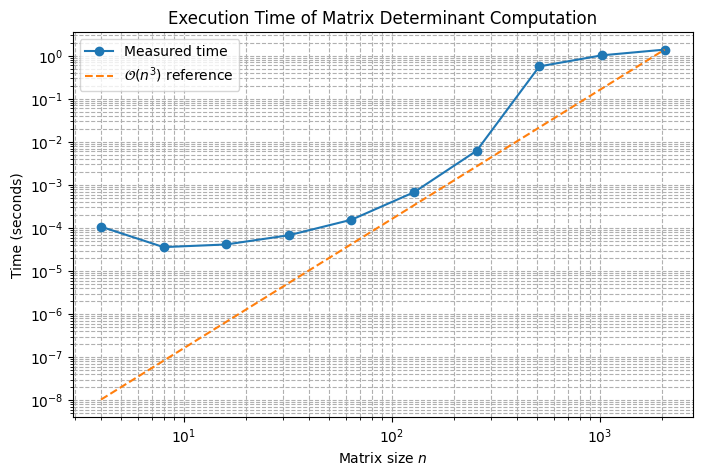

In [7]:
# Plot result:
plt.figure(figsize=(8, 5))
plt.loglog(N, times, 'o-', label='Measured time')

# Reference O(n^3) line for comparison
plt.loglog(N, times[-1] * (N / N[-1])**3, '--', label=r'$\mathcal{O}(n^3)$ reference')

plt.xlabel('Matrix size $n$')
plt.ylabel('Time (seconds)')
plt.title('Execution Time of Matrix Determinant Computation')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()